# Luthera Family Plots

The family data has changed to include the n, s and g variables to try and plot the Secular Resonances.


In [4]:
import pandas as pd
import numpy as np
import h5py as h5
from pathlib import Path
import datetime as datetime

import matplotlib.pyplot as plt
import matplotlib as mpl


In [5]:
project_dir = Path('../../luthera_ast/')
plot_dir = project_dir / 'plots'

path = project_dir / 'luther_proper.h5'
luth_fam = pd.read_hdf(path)

# 2 Body mean motion resonance atlas
path = project_dir / 'MMR_atlas.h5'
mmr_atlas = pd.read_hdf(path)

In [6]:
luth_fam['irad'] = np.arcsin(luth_fam['sineI_P'])
luth_fam['ideg'] = np.degrees(luth_fam['irad'])

p_v = 0.0387

luth_fam['diam']= ((1329 * 10**(-luth_fam['abs_mag']/5)) * (p_v ** (-0.5)))

luth_fam.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
count,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.000000,878.0,878.000000,878.000000,878.000000
mean,16.175513,3.208147,0.123992,0.323863,62.636725,163.961034,-74.485114,259.071526,-10.0,0.329816,18.897053,4.478502
std,0.987079,0.014558,0.008572,0.005743,0.426461,57.980031,1.524164,752.086762,0.0,0.006072,0.347883,3.757710
min,9.480000,3.172780,0.106420,0.312013,61.765176,85.871008,-79.056097,5.500000,-10.0,0.317312,18.180615,1.752546
25%,15.620000,3.196843,0.117742,0.320017,62.306345,118.604830,-75.573336,29.200000,-10.0,0.325747,18.663932,2.829238
50%,16.390000,3.207515,0.123102,0.323137,62.653273,146.082211,-74.454953,82.950000,-10.0,0.329043,18.852771,3.561800
75%,16.890000,3.219394,0.129977,0.327705,62.966784,194.958434,-73.310560,250.000000,-10.0,0.333874,19.129562,5.077729
max,17.930000,3.238196,0.144674,0.340954,63.701778,361.322776,-71.181669,10000.000000,-10.0,0.347932,19.935032,85.836005


In [7]:
mmr_atlas[(mmr_atlas.sma >= 3.0) & (mmr_atlas.sma <= 3.45) & (mmr_atlas.strength >= 1e-12)]

,planet,ratio1,ratio2,sma,ecc,inc,w,ln,R,strength,width,sigma,periods
1022,J,9,4,3.02897,0.15,8.0,60.0,0.0,6.002700e-08,2.793100e-12,0.002366,214 999 999 999,4501.0
1041,J,2,1,3.27640,0.15,8.0,60.0,0.0,6.129500e-08,8.053500e-09,0.150420,5 999 999 999,398.7
1055,J,13,7,3.44233,0.15,8.0,60.0,0.0,6.227300e-08,2.764700e-12,0.002852,36 999 999 999,2938.0


In [8]:
# MMR values in AU
mmrs_3b_luthera = {'6J:3S:1':[3.141,1.0002,0.9985], 
                   '5J:2S:2':[3.174,1.0002,0.9985], 
                   '5J:3S:3':[3.208,1.0002,0.9985]}

def plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_range[0]) & (mmr_atlas.sma <= sma_range[1]) & (mmr_atlas.strength > min_strength)]    

    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        if mmr.sma-mmr.width > sma_range[0]:
            ax.vlines(mmr.sma-mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.vlines(mmr.sma, line_min, line_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_range[1]:
            ax.vlines(mmr.sma+mmr.width, line_min, line_max, linestyles='dashed', alpha=0.25)
        ax.text(mmr.sma*1.0002, line_max * 0.994, label,rotation=90)


def plot_3b_mmr(ax, sma_range, line_min, line_max):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if sma[0] < sma_range[0] or sma[0] > sma_range[1]:
            continue
        ax.vlines(sma[0], line_min, line_max, linestyles='dashed')
        ax.text(sma[0]*sma[1], line_max * 0.993, mmr_nme,rotation=90)


# add the MMR lines in a plot with an semi-major axis (a) x axis.
def plot_mmrs(ax, sma_range, line_min, line_max, min_strength=1e-13):
    plot_2b_mmr(ax, sma_range, line_min, line_max, min_strength)
    plot_3b_mmr(ax, sma_range, line_min, line_max)


mars_a = 1.666
mars_p = 1.381

jupiter_a = 5.367
jupiter_p = 5.035
jupiter_sm = 5.204

# Planetary mean motions
jupiter_n5 = 360/(4333/365.25) 
saturn_n6 = 360/(10759/365.25)
uranus_n7 = 360/(30687/365.25)
neptune_n8 = 360/(60190/365.25)

# Planetary perihelion precession
jupiter_g5 = 4.527
saturn_g6 = 28.243
uranus_g7 = 3.093
neptune_g8 = 0.673

# Planetary node precession
saturn_s6 = -26.345
uranus_s7 = -2.996
neptune_s8 = -0.693

# Find the eccentricities that cause a body to cross the orbit of mars or jupiter
a_range = np.linspace(1.8, 3.9, 1000)

# We want the e for jupiter_p for an a
#d_a = a(1-e)
jupiter_crossing_e = (a_range/jupiter_p)-1
jupiter_q = np.vstack([a_range, jupiter_crossing_e])

mars_crossing_e = 1-(a_range/mars_a)
mars_Q = np.vstack([a_range, mars_crossing_e])

plot_values = np.where((jupiter_q[0,:]>=3.17) & (jupiter_q[0,:]<=3.24))[0]

def plot_js_crossing_e(ax,x_min, x_max):
    plot_values = np.where((jupiter_q[0,:]>=x_min) & (jupiter_q[0,:]<=x_max))[0]
    ax.plot(mars_Q[:,np.array(plot_values)][0],mars_Q[:,np.array(plot_values)][1])
    ax.plot(jupiter_q[:,np.array(plot_values)][0],jupiter_q[:,np.array(plot_values)][1])



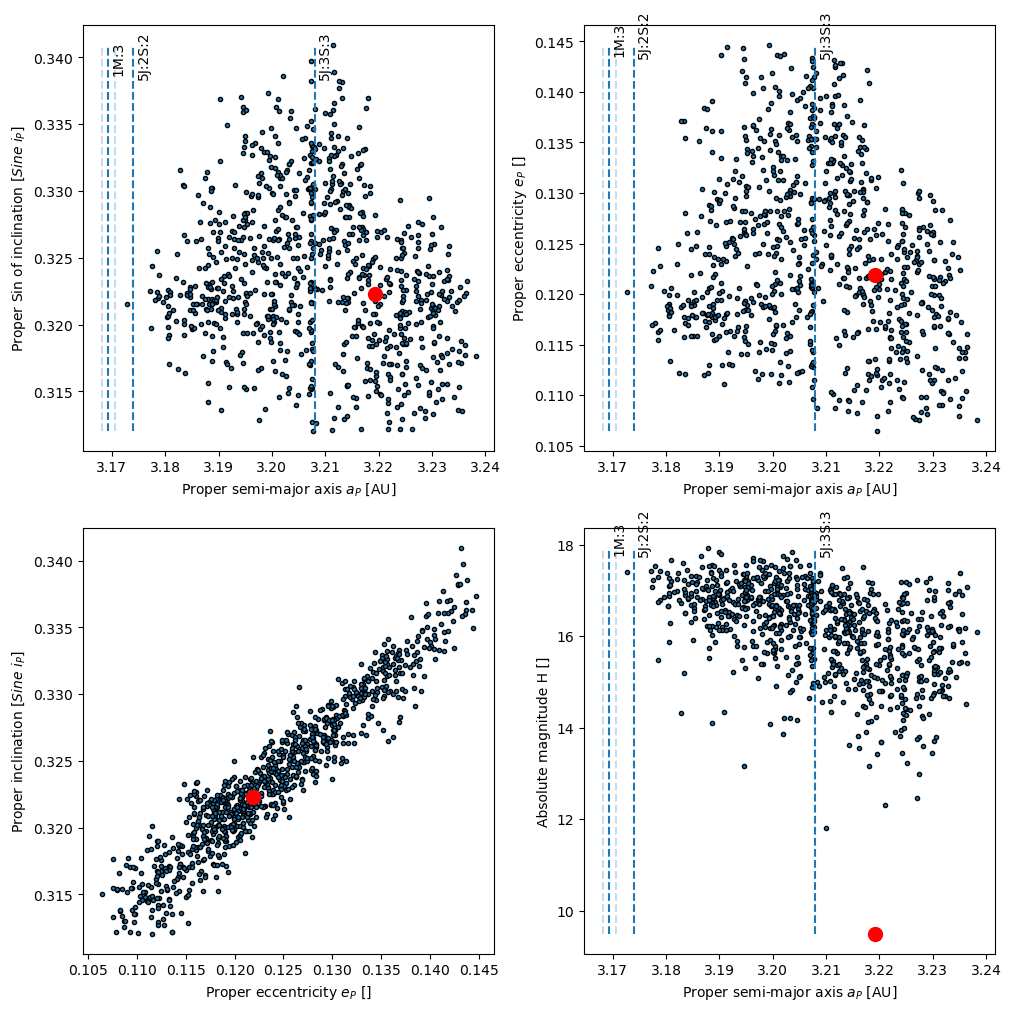

In [9]:
sma_range = (3.15, 3.26)

fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
ax1.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("Proper Sin of inclination [$Sine ~i_P$]")
plot_mmrs(ax1, sma_range, luth_fam.sineI_P.min(), luth_fam.sineI_P.max())

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax2, sma_range, luth_fam.e_P.min(), luth_fam.e_P.max())

ax3 = fig.add_subplot(spec[1, 0])
plt.scatter(data=luth_fam, x='e_P',y='sineI_P' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['e_P','sineI_P']].values
ax3.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax3.set_xlabel("Proper eccentricity $e_P$ []")
ax3.set_ylabel("Proper inclination [$Sine ~i_P$]")

ax4 = fig.add_subplot(spec[1, 1])
ax4.scatter(data=luth_fam, x='a_P',y='abs_mag' , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax4.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax4.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax4.set_ylabel("Absolute magnitude H []")
plot_mmrs(ax4, sma_range, luth_fam.abs_mag.min(), luth_fam.abs_mag.max())

plt.savefig(f"../../dissertation/luthera_prp_ieM.png", dpi=300)
plt.show()


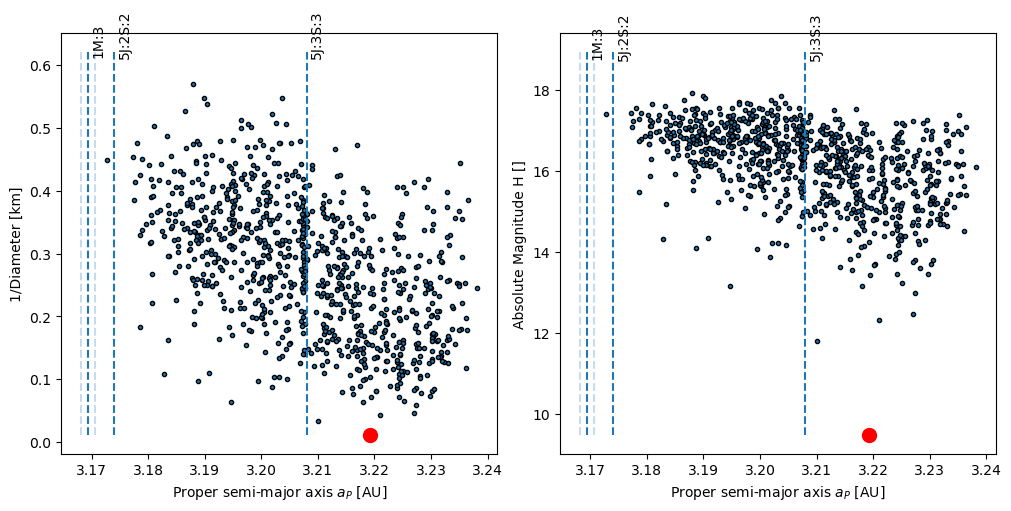

In [10]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

over_D = 1/luth_fam.diam

ax1.scatter(x=luth_fam.a_P,y=over_D, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','diam']].values
ax1.plot(luth_ie[0][0],1/luth_ie[0][1], 'ro', markersize=10)
ax1.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax1.set_ylabel("1/Diameter [km]")
plot_mmrs(ax1, sma_range, over_D.min(), over_D.max()+0.05)

ax2 = fig.add_subplot(spec[0, 1])
ax2.scatter(x=luth_fam.a_P,y=luth_fam.abs_mag , edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','abs_mag']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax2.set_ylabel("Absolute Magnitude H []")
plot_mmrs(ax2, sma_range, luth_fam.abs_mag.min(), luth_fam.abs_mag.max()+1)

plt.savefig(f"../../dissertation/luthera_prp_DM.png", dpi=300)
plt.show()


In [11]:
brights = luth_fam[luth_fam['abs_mag']<13]

brights

,ast_name,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time,irad,ideg,diam
0,1303,9.48,3.219248,0.121842,0.322276,62.310603,193.693422,-75.178531,500.0,-10,0.328133,18.800642,85.836005
1,11911,11.80,3.210027,0.132169,0.330567,62.579772,151.725694,-75.054158,48.8,-10,0.336904,19.303169,29.489642
3,17840,12.46,3.227073,0.122213,0.322861,62.084582,243.861008,-76.365994,123.5,-10,0.328751,18.836035,21.760531
5,33292,12.99,3.227360,0.129485,0.326713,62.075202,246.598756,-77.825804,46.5,-10,0.332824,19.069401,17.047845
15,65871,12.31,3.221049,0.122196,0.322120,62.258472,203.766346,-75.515723,77.5,-10,0.327968,18.791194,23.316830


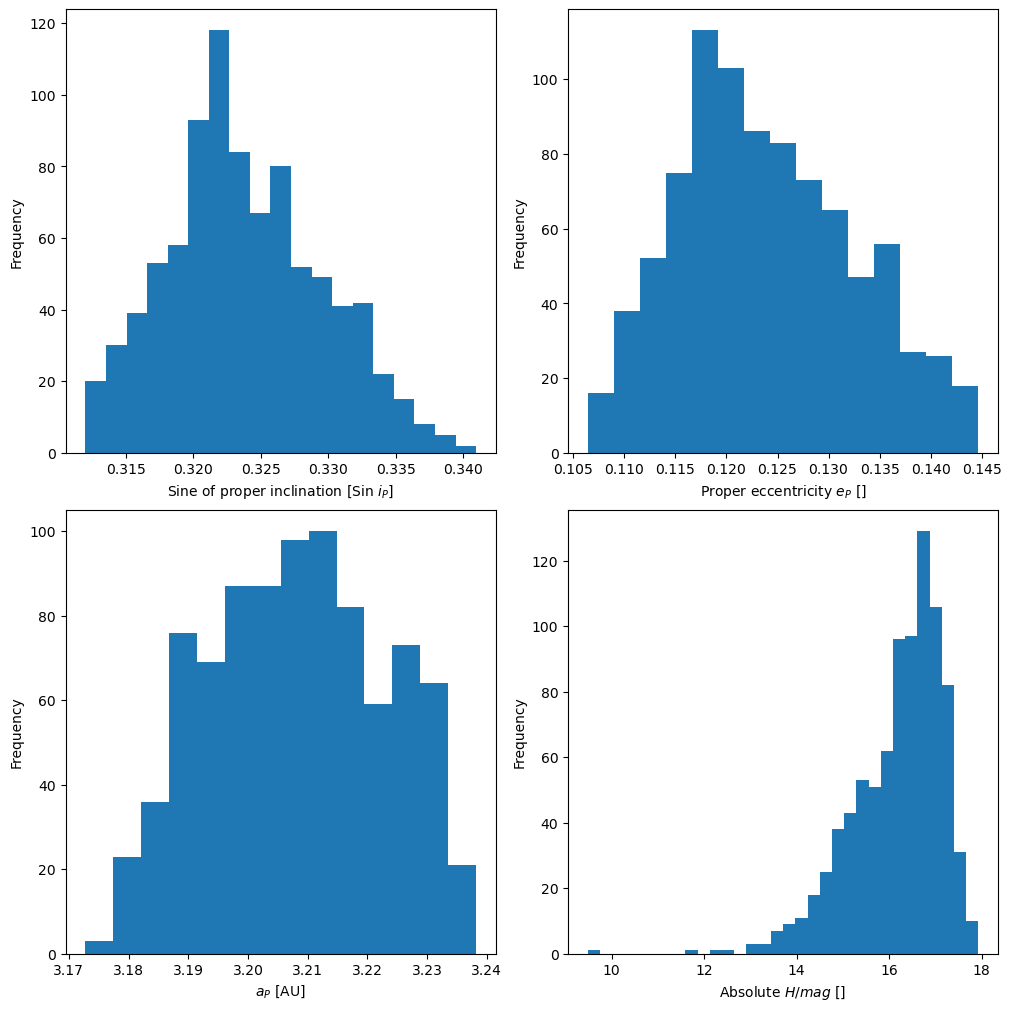

In [12]:
y_label = "Frequency"

fig = plt.figure(figsize=(10, 10), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=2)

ax1 = fig.add_subplot(spec[0, 0])
ax1.hist(data=luth_fam, x='sineI_P', bins='auto')
ax1.set_ylabel(y_label)
ax1.set_xlabel("Sine of proper inclination [Sin $i_P$]")

ax2 = fig.add_subplot(spec[0, 1])
ax2.hist(data=luth_fam, x='e_P', bins='auto')
ax2.set_ylabel(y_label)
ax2.set_xlabel("Proper eccentricity $e_P$ []")

ax3 = fig.add_subplot(spec[1, 0])
ax3.hist(data=luth_fam, x='a_P', bins='auto')
ax3.set_ylabel(y_label)
ax3.set_xlabel("$a_P$ [AU]")

ax4 = fig.add_subplot(spec[1, 1])
ax4.hist(data=luth_fam, x='abs_mag' , bins='auto')
ax4.set_ylabel(y_label)
ax4.set_xlabel("Absolute $H / mag$ []")

plt.savefig(f"../../dissertation/luthera_prp_hist.png", dpi=300)

plt.show()

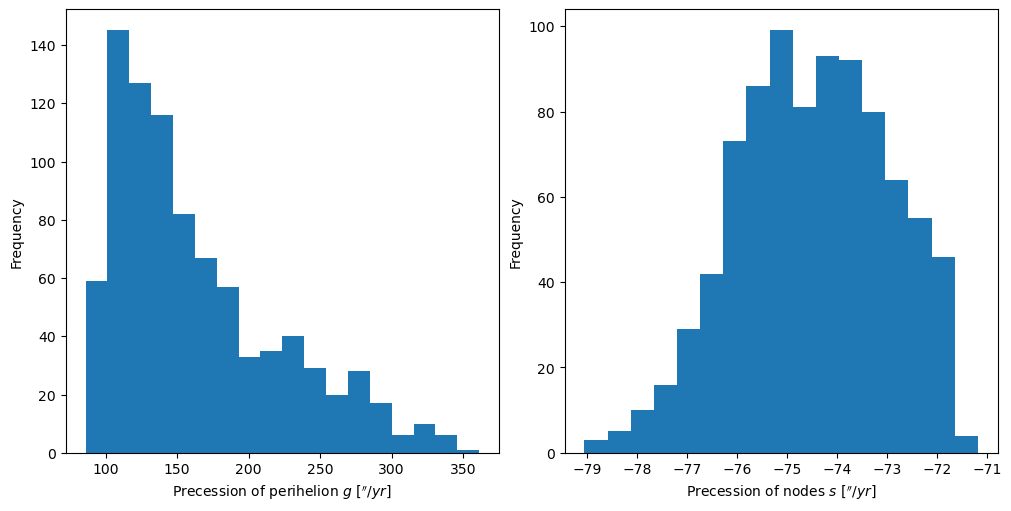

In [13]:
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])

ax1.hist(data=luth_fam, x='g', bins='auto')
ax1.set_ylabel("Frequency")
ax1.set_xlabel("Precession of perihelion $g$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])

ax2.hist(data=luth_fam, x='s', bins='auto')
ax2.set_ylabel("Frequency")
ax2.set_xlabel("Precession of nodes $s$ [$''/yr$]")

plt.savefig(f"../../dissertation/luthera_prp_gs.png", dpi=300)
plt.show()

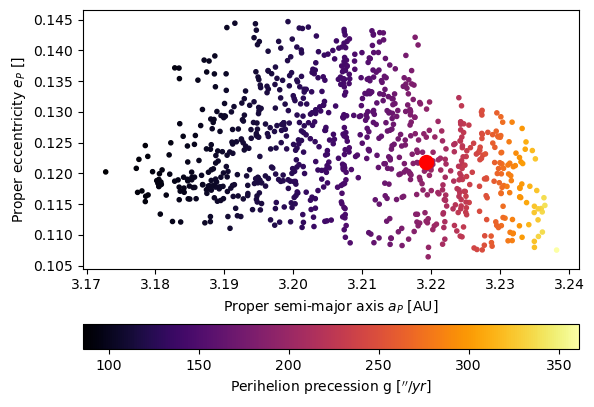

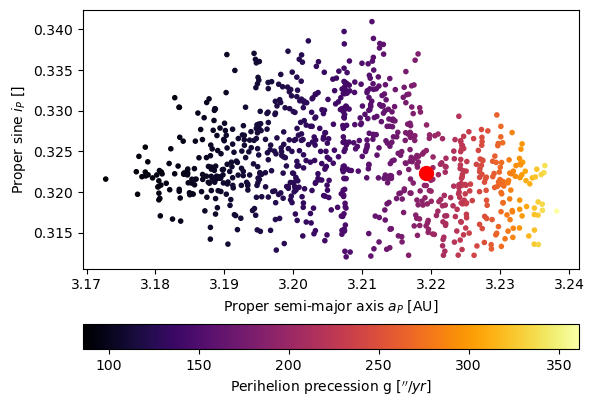

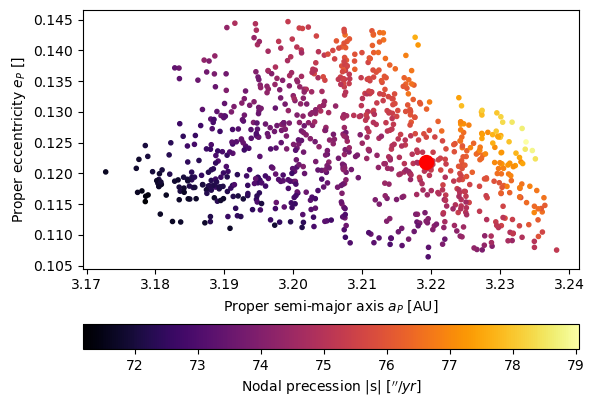

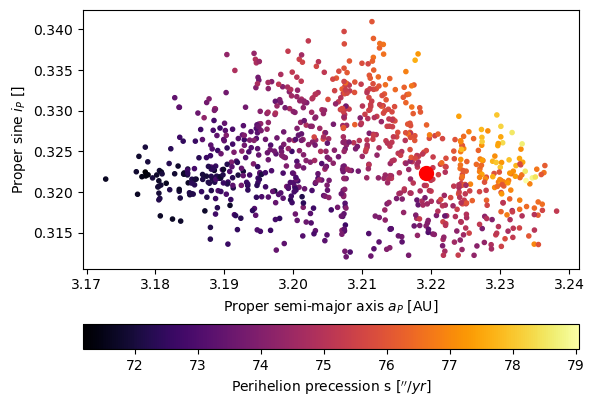

In [14]:
cm_yr = mpl.colormaps['inferno'] 
colour_values = luth_fam['g']

esc = plt.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
plt.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper eccentricity $e_P$ []")
plt.colorbar(esc, label="Perihelion precession g [$\'' / yr$]", location='bottom')

plt.savefig(f"../../dissertation/luthera_prp_ae_g.png", dpi=300)
plt.show()

esc = plt.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
plt.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper sine $i_P$ []")
plt.colorbar(esc, label="Perihelion precession g [$\'' / yr$]", location='bottom')

plt.savefig(f"../../dissertation/luthera_prp_ai_g.png", dpi=300)
plt.show()


cm_yr = mpl.colormaps['inferno'] 
colour_values = np.absolute(luth_fam['s'])

esc = plt.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
plt.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper eccentricity $e_P$ []")
plt.colorbar(esc, label="Nodal precession |s| [$\'' / yr$]", location='bottom')

plt.savefig(f"../../dissertation/luthera_prp_ae_s.png", dpi=300)
plt.show()

esc = plt.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors=None, marker=".",c=colour_values, cmap = cm_yr)
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values
plt.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
plt.xlabel("Proper semi-major axis $a_P$ [AU]")
plt.ylabel("Proper sine $i_P$ []")
plt.colorbar(esc, label="Perihelion precession s [$\'' / yr$]", location='bottom')

plt.savefig(f"../../dissertation/luthera_prp_ai_g.png", dpi=300)
plt.show()


In [15]:
# Estimate the mean motion of a body for a given sma
def n_value(semi_major_axis):
    orbital_p = semi_major_axis**(3/2)
    return (360/orbital_p)

def sma_value(mean_motion):
    orbital_p = 360/mean_motion
    return orbital_p**(2/3)

def nplot_2b_mmr(ax, n_range, y_min, y_max, min_strength=1e-13, y_offset=0.98):
    plt_2b_mmr = mmr_atlas[(mmr_atlas.sma >= sma_value(n_range[1])) & (mmr_atlas.sma <= sma_value(n_range[0])) & 
                            (mmr_atlas.strength > min_strength)]    
    
    for _, mmr in plt_2b_mmr.iterrows():
        label = f"{mmr.ratio1}{mmr.planet[0]}:{mmr.ratio2}"
        if mmr.sma-mmr.width > sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma-mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.vlines(n_value(mmr.sma), y_min, y_max, linestyles='dashed')
        if mmr.sma+mmr.width < sma_value(n_range[0]):
            ax.vlines(n_value(mmr.sma+mmr.width), y_min, y_max, linestyles='dashed', alpha=0.25)
        ax.text(n_value(mmr.sma)*1.0002, (y_max)*y_offset, label,rotation=90)


def nplot_3b_mmr(ax, n_range, y_min, y_max, y_offset=0.98):
    for mmr_nme, sma in mmrs_3b_luthera.items():
        if n_value(sma[0]) < n_range[0] or n_value(sma[0]) > n_range[1]:
            continue
        ax.vlines(n_value(sma[0]), y_min, y_max, linestyles='dashed')
        ax.text(n_value(sma[0]*sma[1]), y_max * 0.993, mmr_nme,rotation=90)

# add the MMR lines in a plot with an mean motion (n) on x axis.
def nplot_mmrs(ax, n_range, y_min, y_max, y_offset=0.9):
    nplot_2b_mmr(ax, n_range, y_min, y_max)
    nplot_3b_mmr(ax, n_range, y_min, y_max)


# Secular resonances map
sec_res_list = [[saturn_g6, r'$\nu_{6}$'],
           [2*saturn_g6-jupiter_g5, '$g-2g_6+g_5$'], 
           [3*saturn_g6-2*jupiter_g5, '$g-3g_6+2g_5$']]

# Plot the secular resonances


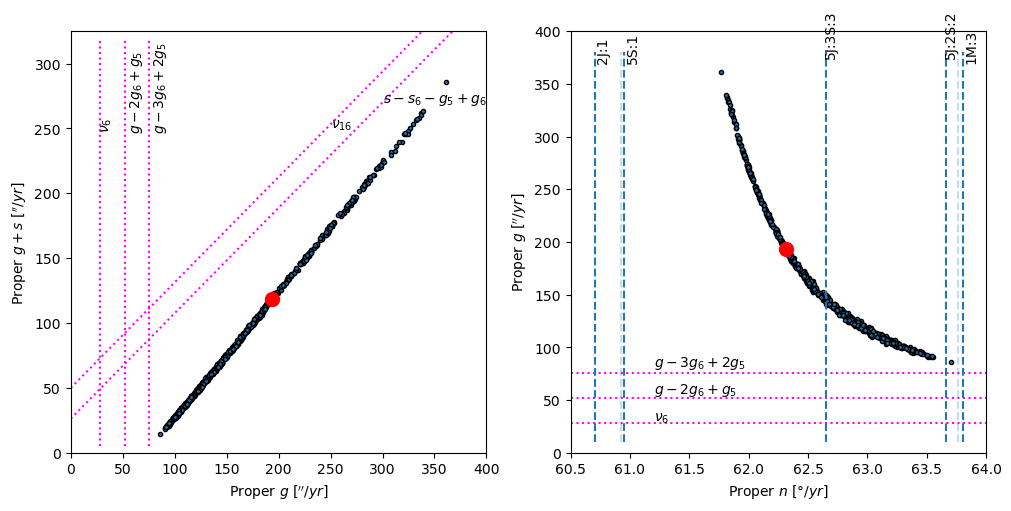

In [16]:
n_range = (60.5,64.0)
fig = plt.figure(figsize=(10, 5), layout="constrained")

spec = fig.add_gridspec(ncols=2, nrows=1)
ax1 = fig.add_subplot(spec[0, 0])
# spec the x and y axes limits
g_range = (0, 400)
gs_range = (0, 325)
ax1.set_xlim(g_range)
ax1.set_ylim(gs_range)
g_s = luth_fam.g+luth_fam.s
ax1.scatter(x=luth_fam.g,y=g_s, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['g','s']].values
ax1.plot(luth_ie[0][0],luth_ie[0][0]+luth_ie[0][1], 'ro', markersize=10)

# v_6 
ax1.vlines(sec_res_list[0][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(28, 250, sec_res_list[0][1],rotation=90)
# g-2g_6+g_5
ax1.vlines(sec_res_list[1][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(55, 250, sec_res_list[1][1],rotation=90)
# g-3g_6+2g_5
ax1.vlines(sec_res_list[2][0], 5, 320, linestyles='dotted', colors='magenta')
ax1.text(78, 250, sec_res_list[2][1],rotation=90)
# s-s_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax1.plot(g_vals, gs_vals-saturn_s6, ls='dotted', c='magenta')
ax1.text(250, 250, r'$\nu_{16}$')
# s-s_6-g_5+g_6
g_vals = np.linspace(g_range[0],g_range[1], 100)
gs_vals = np.linspace(gs_range[0],gs_range[1], 100)
ax1.plot(g_vals, gs_vals-saturn_s6-jupiter_g5+saturn_g6, ls='dotted', c='magenta')
ax1.text(300, 270, r'$s - s_6 - g_5 + g_6$')

ax1.set_xlabel("Proper $g$ [$''/yr$]")
ax1.set_ylabel("Proper $g+s$ [$''/yr$]")

ax2 = fig.add_subplot(spec[0, 1])
# spec the x and y axes limits
ax2.set_xlim(n_range)
ax2.set_ylim((0, 400))

ax2.scatter(x=luth_fam.n,y=luth_fam.g, edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['n','g']].values
ax2.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax2.set_xlabel("Proper $n$ [$\degree/yr$]")
ax2.set_ylabel("Proper $g$ [$''/yr$]")

# Plot the secular resonances
for sec_res in sec_res_list: 
    ax2.hlines(sec_res[0], n_range[0], n_range[1], linestyles='dotted', color='magenta')
    ax2.text(61.2, sec_res[0]*1.08,  sec_res[1])


# plot the MMR in n space
nplot_mmrs(ax2, n_range, 10, 380)

plt.savefig(f"../../dissertation/luthera_prp_ngs.png", dpi=300)
plt.show()

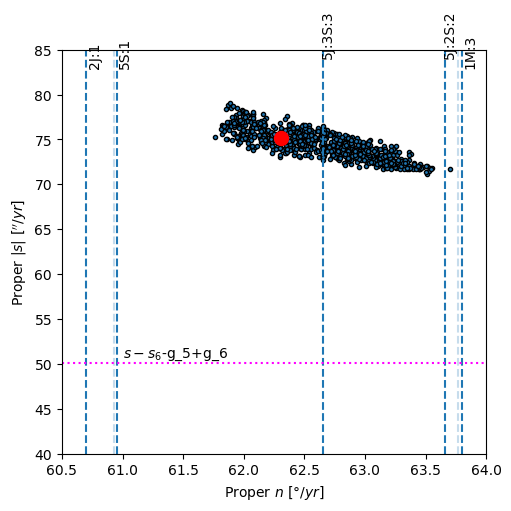

In [17]:
s_range = (40, 85)
fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")

ax.set_xlim(n_range)
ax.set_ylim(s_range)

ax.scatter(x=luth_fam.n,y=np.absolute(luth_fam.s), edgecolors='black', marker=".")
luth_ie = luth_fam[luth_fam.ast_name == '1303'][['n','s']].values
ax.plot(luth_ie[0][0],np.absolute(luth_ie[0][1]), 'ro', markersize=10)
# plot the MMR in n space
nplot_mmrs(ax, n_range, s_range[0], s_range[1], y_offset=0.6)

# Line was too low at around 40
ax.hlines(-saturn_s6-jupiter_g5+saturn_g6,60.5,64,linestyles='dotted', colors='magenta')
ax.text(61.0, 50.7, r'$s - s_6$-g_5+g_6')

ax.set_xlabel("Proper $n$ [$\degree/yr$]")
ax.set_ylabel("Proper $|s|$ [$''/yr$]")
plt.savefig(f"../../dissertation/luthera_prp_ns.png", dpi=300)
plt.show()

In [15]:
print(2*jupiter_n5)
print(n_value(3.10))

60.69236095084237
65.95685817062689


In [16]:
mvc3_1g = 2.4 * 24 * 3600
mc3_1g = (19/24) * 24 * 3600
cluster_p = 700
tot_simulations = 19050

print(f"mvc3_1g Expected time with {cluster_p: 5} cores:{datetime.timedelta(seconds=mvc3_1g * (tot_simulations/cluster_p))}")

print(f"mvc3_1g Expected time with {cluster_p*10: 5} cores: {datetime.timedelta(seconds=mvc3_1g *(tot_simulations/(cluster_p*10)))}")

print(f"mc3_1g  Expected time with {cluster_p: 5} cores:{datetime.timedelta(seconds=mc3_1g *(tot_simulations/cluster_p))}")

print(f"mc3_1g  Expected time with {cluster_p*10: 5} cores: {datetime.timedelta(seconds=mc3_1g *(tot_simulations/(cluster_p*10)))}")


mvc3_1g Expected time with   700 cores:65 days, 7:32:34.285714
mvc3_1g Expected time with  7000 cores: 6 days, 12:45:15.428571
mc3_1g  Expected time with   700 cores:21 days, 13:04:17.142857
mc3_1g  Expected time with  7000 cores: 2 days, 3:42:25.714286


In [17]:
month = 30 * 24 * 3600
print(f"Month of sims each 1.4 days {cluster_p*(month/mvc3_1g)}")

Month of sims each 1.4 days 8750.000000000002


## Plot a asteroid family context scatter 
this plot includes: 
* Jupiter and Mars crossing lines
* MMR resonance lines
* Secular resonance lines


In [18]:
all_proper = pd.read_hdf(project_dir / 'afp_proper_elements.h5')

In [19]:
#define the neighbourhood
luth_a_min = luth_fam.a_P.min()
luth_a_max = luth_fam.a_P.max()

luth_i_min = luth_fam.sineI_P.min()
luth_i_max = luth_fam.sineI_P.max()

range_ratio = 2.5
a_range = (luth_a_max-luth_a_min)
neighbr_a_min = 3.0 #luth_a_min - (a_range*range_ratio)
neighbr_a_max = 3.45 #luth_a_max + (a_range*range_ratio)

i_range = (luth_i_max-luth_i_min)
neighbr_i_min = luth_i_min - (i_range*range_ratio)
neighbr_i_max = luth_i_max + (i_range*range_ratio)

neighbr_asteroids = all_proper[(all_proper.a_P>=neighbr_a_min) & (all_proper.a_P<=neighbr_a_max) &
                                (all_proper.sineI_P>=neighbr_i_min) & (all_proper.sineI_P<=neighbr_i_max)]
neighbr_asteroids.describe()

,abs_mag,a_P,e_P,sineI_P,n,g,s,lyap_time,My_int_time
count,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.000000,66293.0
mean,16.295650,3.134314,0.158051,0.293167,64.903815,90.845231,-82.548145,1138.106263,-10.0
std,1.157924,0.060499,0.072577,0.038810,1.856100,57.359570,17.174801,8053.192422,0.0
min,6.180000,3.000008,0.000969,0.239663,56.171621,-695.267876,-269.982536,0.100000,-10.0
25%,15.720000,3.092251,0.097592,0.267641,63.640657,61.346503,-90.720607,12.000000,-10.0
50%,16.540000,3.134456,0.166879,0.285234,64.854916,75.047265,-78.787544,47.400000,-10.0
75%,17.090000,3.174137,0.208493,0.306804,66.186659,105.509435,-70.433910,270.300000,-10.0
max,19.360000,3.449340,0.463888,0.413267,69.266750,666.102477,-10.022626,100000.000000,-10.0


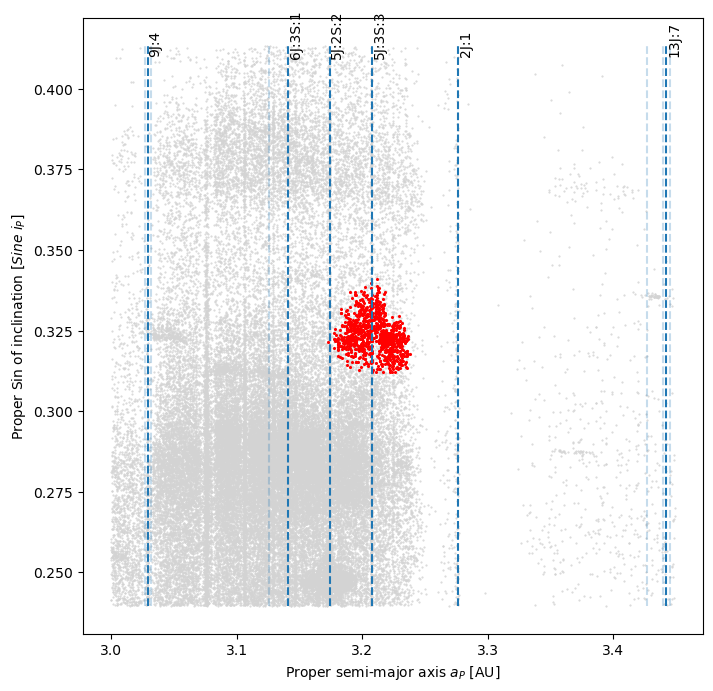

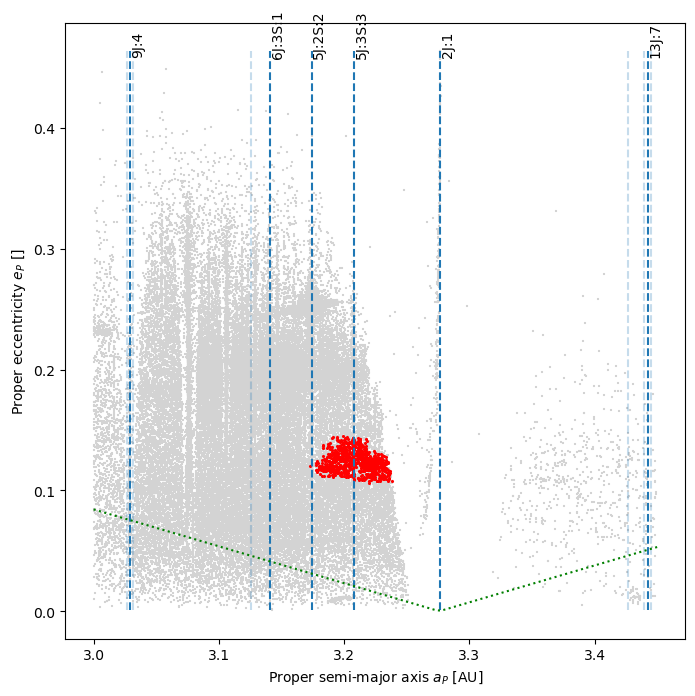

In [20]:
sma_range = (neighbr_a_min, neighbr_a_max)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(data=neighbr_asteroids, x='a_P',y='sineI_P', marker=".", c='lightgrey', s=1)
ax.scatter(data=luth_fam, x='a_P',y='sineI_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','sineI_P']].values

ax.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)

ax.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax.set_ylabel("Proper Sin of inclination [$Sine ~i_P$]")

plot_mmrs(ax, sma_range, neighbr_i_min, neighbr_i_max, min_strength=1e-12)

plt.savefig(plot_dir / "neighbour_ai.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(data=neighbr_asteroids, x='a_P',y='e_P', marker="+", c='lightgrey', s=1)
ax.scatter(data=luth_fam, x='a_P',y='e_P', edgecolors='red', marker="*", c='red', s=2)

luth_ie = luth_fam[luth_fam.ast_name == '1303'][['a_P','e_P']].values
ax.plot(luth_ie[0][0],luth_ie[0][1], 'ro', markersize=10)
ax.set_xlabel("Proper semi-major axis $a_P$ [AU]")
ax.set_ylabel("Proper eccentricity $e_P$ []")
plot_mmrs(ax, sma_range, neighbr_asteroids.e_P.min(), neighbr_asteroids.e_P.max(), min_strength=1e-12)
plot_crossing_e(ax, sma_range[0], sma_range[1], 3.276)
plt.savefig(plot_dir / "neighbour_ae.png", dpi=300)
plt.show()


In [31]:

## From Tim
#---Apehilion and Perihelion lines

##q - perihelion
"""xsmau = np.linspace(1, limit, 100)
ysmau = 0.9833 -(1/xsmau)
plt.plot(xsmau, ysmau, color = 'white')

##Q - apheion
xsmal = np.linspace(0, limit, 100)
ysmal =  (1/xsmal) - 1.0167
plt.plot(xsmal, ysmal, color = 'white')
"""
def calc_crossing_e_th(sma_p, sma_a, limit):
    sma_range = np.linspace(sma_a, sma_a+limit, 10)
    ecc_pvals = sma_p -(1/sma_range)
    ae_pvals = np.vstack([sma_range, ecc_pvals])
    
    sma_range = np.linspace(sma_p-limit, sma_p, 10)
    ecc_avals =  (1/sma_range) - sma_a
    ae_avals = np.vstack([sma_range, ecc_avals])
    return ae_pvals, ae_avals

def plot_crossing_e(ax, sma_min, sma_max, sma):
    a_range = np.linspace(sma_min, sma_max, 100)

    if sma > sma_max:
        crossing_e = 1-(a_range/sma) 
    elif sma > sma_min and sma < sma_max:
        sma_index = np.where(a_range >= sma)[0]
        crossing_e_1 = 1-(a_range[:sma_index[0]]/sma)
        crossing_e_2 = (a_range[sma_index[0]:]/sma) - 1
        crossing_e = np.concatenate([crossing_e_1, crossing_e_2])
        #print(crossing_e)
    else:
        crossing_e = (a_range/sma)-1
        
    crossing_sma_e = np.vstack([a_range, crossing_e])
    #print(crossing_sma_e)
    #print(crossing_sma_e.shape)
    
    plot_values = np.where((crossing_sma_e[0,:]>=sma_min) & (crossing_sma_e[0,:]<=sma_max))[0]
    # print(plot_values)
    ax.plot(crossing_sma_e[:,np.array(plot_values)][0],crossing_sma_e[:,np.array(plot_values)][1], 'g:')


In [34]:
e = 0.0489
j_ax = 5.2038
j21_ax = 3.85

pe = j_ax*(1-e)
ap = j_ax*(1+e)
print(f'Jupiter parameters semimajor axis:{j_ax}, eccentricity:{e}, perihelion:{pe}, aphelion:{ap}')

pe = j21_ax*(1-e)
ap = j21_ax*(1+e)
print(f'MMR 2J:1 parameters semimajor axis:{j21_ax}, eccentricity:{e}, perihelion:{pe}, aphelion:{ap}\n')

a_range = np.linspace(4.9, 5.0, 10)
print(list(zip(a_range, 1-(a_range/j_ax))),'\n')

a_range = np.linspace(5.4, 5.5, 10)
print(list(zip(a_range, (a_range/j_ax)-1)),'\n')

e_ax = 1
e_pe = 0.9833
e_ap = 1.0167

p_vals, a_vals = calc_crossing_e_th(e_pe,e_ap, 0.9832)

print(list(zip(p_vals)),'\n')

a_range = np.linspace(0.1, e_pe, 10)
print(list(zip(a_range, 1-(a_range/e_ax))),'\n')

a_range = np.linspace(e_ap, 2.5, 10)
print(list(zip(a_range, (a_range/e_ax)-1)),'\n')



Jupiter parameters semimajor axis:5.2038, eccentricity:0.0489, perihelion:4.94933418, aphelion:5.45826582
MMR 2J:1 parameters semimajor axis:3.85, eccentricity:0.0489, perihelion:3.661735, aphelion:4.038265

[(4.9, 0.058380414312617646), (4.911111111111111, 0.056245222508337855), (4.9222222222222225, 0.054110030704058176), (4.933333333333334, 0.051974838899778386), (4.944444444444445, 0.049839647095498596), (4.955555555555556, 0.047704455291218806), (4.966666666666667, 0.045569263486939016), (4.977777777777778, 0.043434071682659225), (4.988888888888889, 0.041298879878379546), (5.0, 0.039163688074099756)] 

[(5.4, 0.037703216879972246), (5.411111111111111, 0.039838408684252036), (5.4222222222222225, 0.041973600488531826), (5.433333333333334, 0.044108792292811616), (5.444444444444445, 0.046243984097091406), (5.455555555555556, 0.048379175901371196), (5.466666666666667, 0.05051436770565099), (5.477777777777778, 0.05264955950993078), (5.488888888888889, 0.05478475131421057), (5.5, 0.056919